# **Sesión 3:** Procesamiento de imagenes y extracción de características

## **Librerías**

In [1]:
import numpy as np
import cv2
import os
import imageio
from typing import List
import glob
import matplotlib.pyplot as plt
import itertools

## **Apartado C: Detección de esquinas**

El objetivo de este apartado es detectar las esquinas presentes en las imágenes de la carpeta ``data/partC/source``.

1. **Tarea C.1**. Cree una nueva capeta llamada ``partC_processed``, dentro de la carpeta  ``data/partC/source``, con el objetivo de presentar en ella los resultados de esta parte de la práctica.
2. **Tarea C.2**. Defina y ejecute los dos métodos propuestos para cargar imágenes ``imageio_load_images()`` y ``opencv_load_images()``. Observe lo que ocurre al guardar ambas imágenes usando la misma función ``cv2.imwrite()``.
3. **Tarea C.3.** Defina la función ``harris_corner_detector()``, que servirá para la posterior aplicación sobre las imágenes de trabajo. 
4. **Tarea C.4.** Aplique la función ``harris_corner_detector()`` sobre las imágenes de trabajo. Asegúrese de que las imágenes quedan guardadas como se especifica en los comentarios.
5. **Tarea C.5.** Defina la función ``shi_tomasi_corner_detection()``, que servirá para la posterior aplicación sobre las imágenes de trabajo.
6. **Tarea C.6.** Aplique la función ``shi_tomasi_corner_detection()`` sobre las imágenes de trabajo. Asegúrese de que las imágenes quedan guardadas como se especifica en los comentarios.

### **Tarea C.1**. Cree una nueva capeta llamada ``partC_processed``, dentro de la carpeta  ``data/partC/source``, con el objetivo de presentar en ella los resultados de esta parte de la práctica.

In [2]:
# TODO Create a folder to save all partC results (inside data)
folder_name = "partC_processed"  # el nombre que va a tener la carpeta
folder_path = os.path.join("..", "data", "partC", "source", folder_name)  
# como tiene que estar dentro de la carpeta data, tenemos que salir de la carpeta src en la que estamos actualmente ".."
os.makedirs(name=folder_path, exist_ok=True)  # usamos exist_ok = True por si acaso la carpeta ya existe para que no salte ningún error o excepción

### **Tarea C.2**. Defina y ejecute los dos métodos propuestos para cargar imágenes ``imageio_load_images()`` y ``opencv_load_images()``. Observe lo que ocurre al guardar ambas imágenes usando la misma función ``cv2.imwrite()``.

In [3]:
# This initial part is to highlight that cv2.imshow() and cv2.imwrite() works well with previous BGR conversion
def imageio_load_images(filenames: List) -> List:
    '''
    Load images using imageio.imread function (RGB)
    '''
    return [imageio.v2.imread(filename) for filename in filenames]

def opencv_load_images(filenames: List) -> List:
    '''
    Load images cv2.imread function (BGR)
    '''
    return [cv2.imread(filename) for filename in filenames]

# TODO Create two sorted lists with the paths of all images in the data/source folder using glob
imgs_C_path_png = '../data/partC/*.png' # Patrón que cumplen todos los paths de los archivos de imágenes png de la carpeta data/partC
imgs_C_path_jpg = '../data/partC/*.jpg' # Patrón que cumplen todos los paths de los archivos de imágenes jpg de la carpeta data/partC

source_paths = sorted(glob.glob(imgs_C_path_png) + glob.glob(imgs_C_path_jpg))  # Cogemos todos los paths que cumplen algunos de los patrones genéricos (usando glob) y los ordenamos (usando sorted)
imageio_images = imageio_load_images(source_paths)  # Cargamos las imágenes con imageio.v2.imread
opencv_images = opencv_load_images(source_paths)  # Cargamos las imágenes con cv2.imread

# TODO Last element of both image lists is a blue tennis court, so try saving them in partC folder 
# (asumimos que el enunciado se refiere a guardarlas en la carpeta del apartado C, que es en el que estamos)

cv2.imwrite(os.path.join(folder_path, "tennis_court_imageio.jpg"), imageio_images[-1])  
cv2.imwrite(os.path.join(folder_path, "tennis_court_opencv.jpg"), opencv_images[-1])
# Estamos cargando ambas imágenes con la función de OpenCv

True

Al guardar ambas imágenes con la misma función cv2.imwrite(), se observa que la imagen cargada con opencv.imread() mantiene sus colores originales (azul y verde), mientras que la imagen cargada con imageio.v2.imread() aparece con los colores alterados (donde había azul ahora se ve rojo).

Esto ocurre porque cada librería utiliza un orden distinto de canales de color al leer las imágenes:

- OpenCV (cv2) carga las imágenes en formato BGR (Blue, Green, Red).

- ImageIO (al igual que Matplotlib) carga las imágenes en formato RGB (Red, Green, Blue).

Cuando ambas imágenes se guardan con cv2.imwrite(), esta función no realiza ninguna conversión de color, sino que interpreta directamente los valores numéricos de los píxeles que recibe.
Por tanto, si le pasamos una imagen en formato RGB (como la de imageio), OpenCV la trata erróneamente como si fuera BGR, intercambiando los canales rojo y azul.

### **Tarea C.3.** Defina la función ``harris_corner_detector()``, que servirá para la posterior aplicación sobre las imágenes de trabajo. 

In [ ]:
# TODO Define Harris Corner detection function
def harris_corner_detector(image: np.array, blockSize: int, ksize: int, k: float):
    '''
    image - Input image 
    blockSize - Size of neighborhood considered for corner detection
    ksize - Aperture parameter of the Sobel derivative used
    k - Harris detector free parameter in the equation.
    '''
    # TODO Input image to Harris corner detector should be grayscale 
    gray = cv2.cvtColor(src=image, code=cv2.COLOR_BGR2GRAY)

    # TODO Input image to Harris corner detector should be float32 type
    gray = gray.astype(np.float32)

    # TODO Apply Harris corner detection
    harris = cv2.cornerHarris(src=gray, blockSize=blockSize, ksize=ksize, k=k)
    
    # Result is dilated for marking the corners, not important
    harris = cv2.dilate(src=harris, kernel=None)
    
    # TODO Threshold for an optimal value of 1% of maximal R value
    # If pixel value > 1% max value, yo should to hightlight this as a red corner
    max_val = np.max(harris)  # sacamos el valor máximo
    th = 0.01*max_val  # definimos nuestro usando 0.01 
    for fila in range(harris.shape[0]):
        for columna in range(harris.shape[1]):
            if harris[fila][columna] > th:  # comparamos todos los pixeles con el valor del threshold
                image[fila][columna] = [0, 0, 255]  # en caso de complirse la condición, ponemos un máximo de rojo (esta en BGR por lo que es el tercer canal)
                # el marcado en rojo se hace inplace sobre image, por eso convendrá hacer una copia de dicha imagen antes de usar esta función

    return image

### **Tarea C.4.** Aplique la función ``harris_corner_detector()`` sobre las imágenes de trabajo. Asegúrese de que las imágenes quedan guardadas como se especifica en los comentarios.

In [5]:
# This section is designed to to change corner detection parameters for each image
# We want to save processed image in path: Lab3/data/partC-D-E/Harris_{save_name}.jpg

# Primero creamos la carpeta donde se nos pide que guardemos las imágenes
folder_name = "partC-D-E"  # el nombre que va a tener la carpeta
folder_path = os.path.join("..", "data", folder_name)  
# como tiene que estar dentro de la carpeta data, tenemos que salir de la carpeta src en la que estamos actualmente ".."
os.makedirs(name=folder_path, exist_ok=True)  # usamos exist_ok = True por si acaso la carpeta ya existe para que no salte ningún error o excepción

# Definimos los parámetros que vamos a usar para la función de detección de bordes de Harris (buscando ejemplos en internet y documentaciones parece que son valores aceptables)
blockSize = 2
ksize = 3
k = 0.04

In [6]:
# Vemos el orden de imágenes que habíamos guardado, para saber el índice que corresponde a cada una
source_paths

# La de geometry es la segunda (indice 1) y la de football es la primera (indice 0) 

['../data/partC\\football.png',
 '../data/partC\\geometry.jpg',
 '../data/partC\\sudoku.png',
 '../data/partC\\tennis.png']

In [7]:
# First image
save_name = "geometry"

# TODO Copy first original image
image = opencv_images[1].copy()

# TODO Apply Harris Corner Detection
harris_image = harris_corner_detector(image, blockSize = blockSize, ksize = ksize, k = k)

# TODO Save final image in partC folder
cv2.imwrite(os.path.join(folder_path, f"Harris_{save_name}.jpg"), harris_image)

# Second image
save_name = "football"

# TODO Copy second original image
image = opencv_images[0].copy()

# TODO Apply Harris Corner Detection
harris_image = harris_corner_detector(image, blockSize = blockSize, ksize = ksize, k = k)

# TODO Save final image in partC folder
cv2.imwrite(os.path.join(folder_path, f"Harris_{save_name}.jpg"), harris_image)


True

### **Tarea C.5.** Defina la función ``shi_tomasi_corner_detection()``, que servirá para la posterior aplicación sobre las imágenes de trabajo.

In [8]:
# TODO Define Shi-Tomasi corner detection function
def shi_tomasi_corner_detection(image: np.array, maxCorners: int, qualityLevel:float, minDistance: int, corner_color: tuple, radius: int):
    '''
    image - Input image
    maxCorners - Maximum number of corners to return. 
                 If there are more corners than are found, the strongest of them is returned. 
                 maxCorners <= 0 implies that no limit on the maximum is set and all detected corners are returned
    qualityLevel - Parameter characterizing the minimal accepted quality of image corners. 
                   The parameter value is multiplied by the best corner quality measure, which is the minimal eigenvalue or the Harris function response. 
                   The corners with the quality measure less than the product are rejected. 
                   For example, if the best corner has the quality measure = 1500, and the qualityLevel=0.01 , then all the corners with the quality measure less than 15 are rejected
    minDistance - Minimum possible Euclidean distance between the returned corners
    corner_color - Desired color to highlight corners in the original image
    radius - Desired radius (pixels) of the circle
    '''
    # TODO Input image to Tomasi corner detector should be grayscale 
    gray = cv2.cvtColor(src=image, code=cv2.COLOR_BGR2GRAY)

    # TODO Apply cv2.goodFeaturesToTrack function
    corners = cv2.goodFeaturesToTrack(
        image=gray, 
        maxCorners=maxCorners, 
        qualityLevel=qualityLevel, 
        minDistance=minDistance)  # obtenemos los corners llamando a la función de goodFeaturesToTrack que hereda los parámetros que ya nos han pasado previamente
    
    # TODO Corner coordinates conversion to integers
    corners = np.intp(corners)  # con esta función de numpy conseguimos que todas las coordenadas sean del tipo entero
    
    for corner in corners:  # iteramos por cada uno de los corners encontrados, y hacemos un círculo sobre él para marcarlo bien

        # Multidimensional array into flattened array, if necessary
        x, y = corner.ravel()  # de esta forma obtenemos las coordenadas de cada uno de los corners detectados, que nos sirven como centro del círculo que vamos a trazar

        # TODO Circle corners
        cv2.circle(image, center=(x,y), radius=radius, color=corner_color)  
        # el círculo se hace inplace sobre image, por eso convendrá hacer una copia de dicha imagen antes de usar esta función

    return image

### **Tarea C.6.** Aplique la función ``shi_tomasi_corner_detection()`` sobre las imágenes de trabajo. Asegúrese de que las imágenes quedan guardadas como se especifica en los comentarios.

In [9]:
# This section is designed to to change corner detection parameters for each image
# We want to save processed image in path: Lab3/data/partC-D-E/Shi-Tomasi_{save_name}.jpg

# Primero creamos la carpeta donde se nos pide que guardemos las imágenes (ya debería estar creada de antes, pero de esta forma nos aseguramos de ello para evitar errores)
folder_name = "partC-D-E"  # el nombre que va a tener la carpeta
folder_path = os.path.join("..", "data", folder_name)  
# como tiene que estar dentro de la carpeta data, tenemos que salir de la carpeta src en la que estamos actualmente ".."
os.makedirs(name=folder_path, exist_ok=True)  # usamos exist_ok = True por si acaso la carpeta ya existe para que no salte ningún error o excepción

# Definimos los parámetros que vamos a usar para la función de detección de bordes de Harris (buscando ejemplos en internet y documentaciones parece que son valores aceptables)
maxCorners = 50
qualityLevel = 0.05 # no lo dejamos muy bajo para que no nos detecte corners de mala calidad
minDistance = 10
radius = 4

In [10]:
# First image - Purple corners and radius = 4
save_name = "geometry"

# TODO Purple color in adequate color space
purple_color = (128, 0, 128)  # puesto en RGB

# TODO Copy first original image
image = opencv_images[1].copy()

# TODO Apply Shi-Tomasi corner detection
tomasi_image = shi_tomasi_corner_detection(image, maxCorners = maxCorners, qualityLevel = qualityLevel, minDistance = minDistance, corner_color = purple_color, radius = radius)

# TODO Save final image in partC folder
cv2.imwrite(os.path.join(folder_path, f"Shi-Tomasi_{save_name}.jpg"), tomasi_image)

# Second image - Orange corners and radius = 4
save_name = "football"

# TODO Orange color in adequate color space
orange_color = (0, 165, 255)  # puesto en RGB

# TODO Copy second original image
image = opencv_images[0].copy()
tomasi_image = shi_tomasi_corner_detection(image, maxCorners = maxCorners, qualityLevel = qualityLevel, minDistance = minDistance, corner_color = orange_color, radius = radius)

# TODO Save final image in partC folder
cv2.imwrite(os.path.join(folder_path, f"Shi-Tomasi_{save_name}.jpg"), tomasi_image)

True

### Gráficos Adicionales:

#### Comparando ambos métodos fijando unos parámetros:

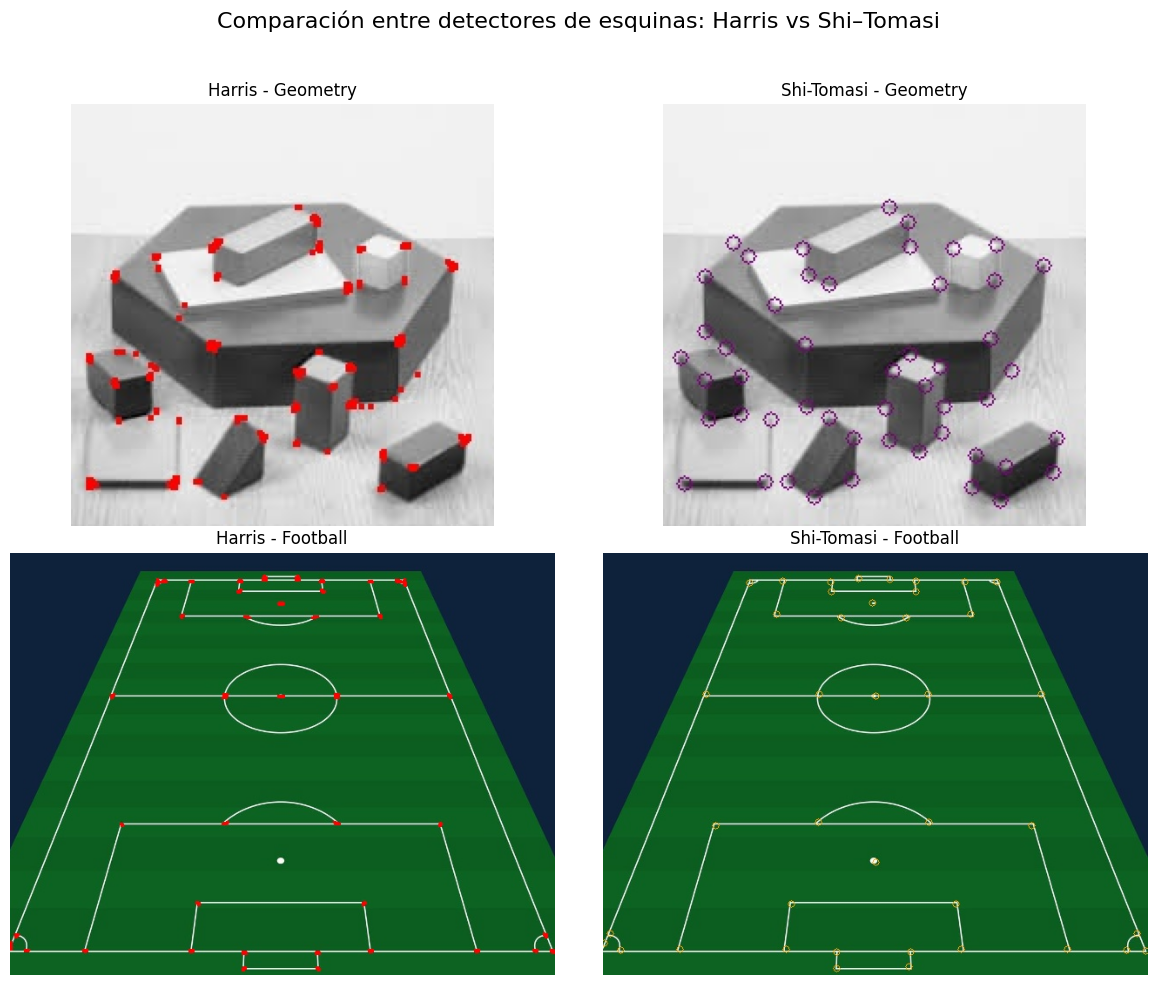

In [20]:
# Rutas de las imágenes guardadas
folder_path = os.path.join("..", "data", "partC-D-E")

# Nombres de archivo
imgs_names = ["geometry", "football"]

# Cargamos las imágenes procesadas con Harris y Shi–Tomasi
harris_results = [cv2.imread(os.path.join(folder_path, f"Harris_{name}.jpg")) for name in imgs_names]
tomasi_results = [cv2.imread(os.path.join(folder_path, f"Shi-Tomasi_{name}.jpg")) for name in imgs_names]

# Convertimos BGR → RGB para mostrarlas correctamente con Matplotlib
harris_results = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in harris_results]
tomasi_results = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in tomasi_results]

# Creamos figura: 2 filas (una por imagen), 2 columnas (Harris / Shi-Tomasi)
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# Primera fila → imagen geometry
ax[0, 0].imshow(harris_results[0])
ax[0, 0].set_title("Harris - Geometry")
ax[0, 0].axis("off")

ax[0, 1].imshow(tomasi_results[0])
ax[0, 1].set_title("Shi-Tomasi - Geometry")
ax[0, 1].axis("off")

# Segunda fila → imagen football
ax[1, 0].imshow(harris_results[1])
ax[1, 0].set_title("Harris - Football")
ax[1, 0].axis("off")

ax[1, 1].imshow(tomasi_results[1])
ax[1, 1].set_title("Shi-Tomasi - Football")
ax[1, 1].axis("off")

# Título general y ajuste
plt.suptitle("Comparación entre detectores de esquinas: Harris vs Shi–Tomasi", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### Comparando el mismo método con distintas combinaciones de parámetros:

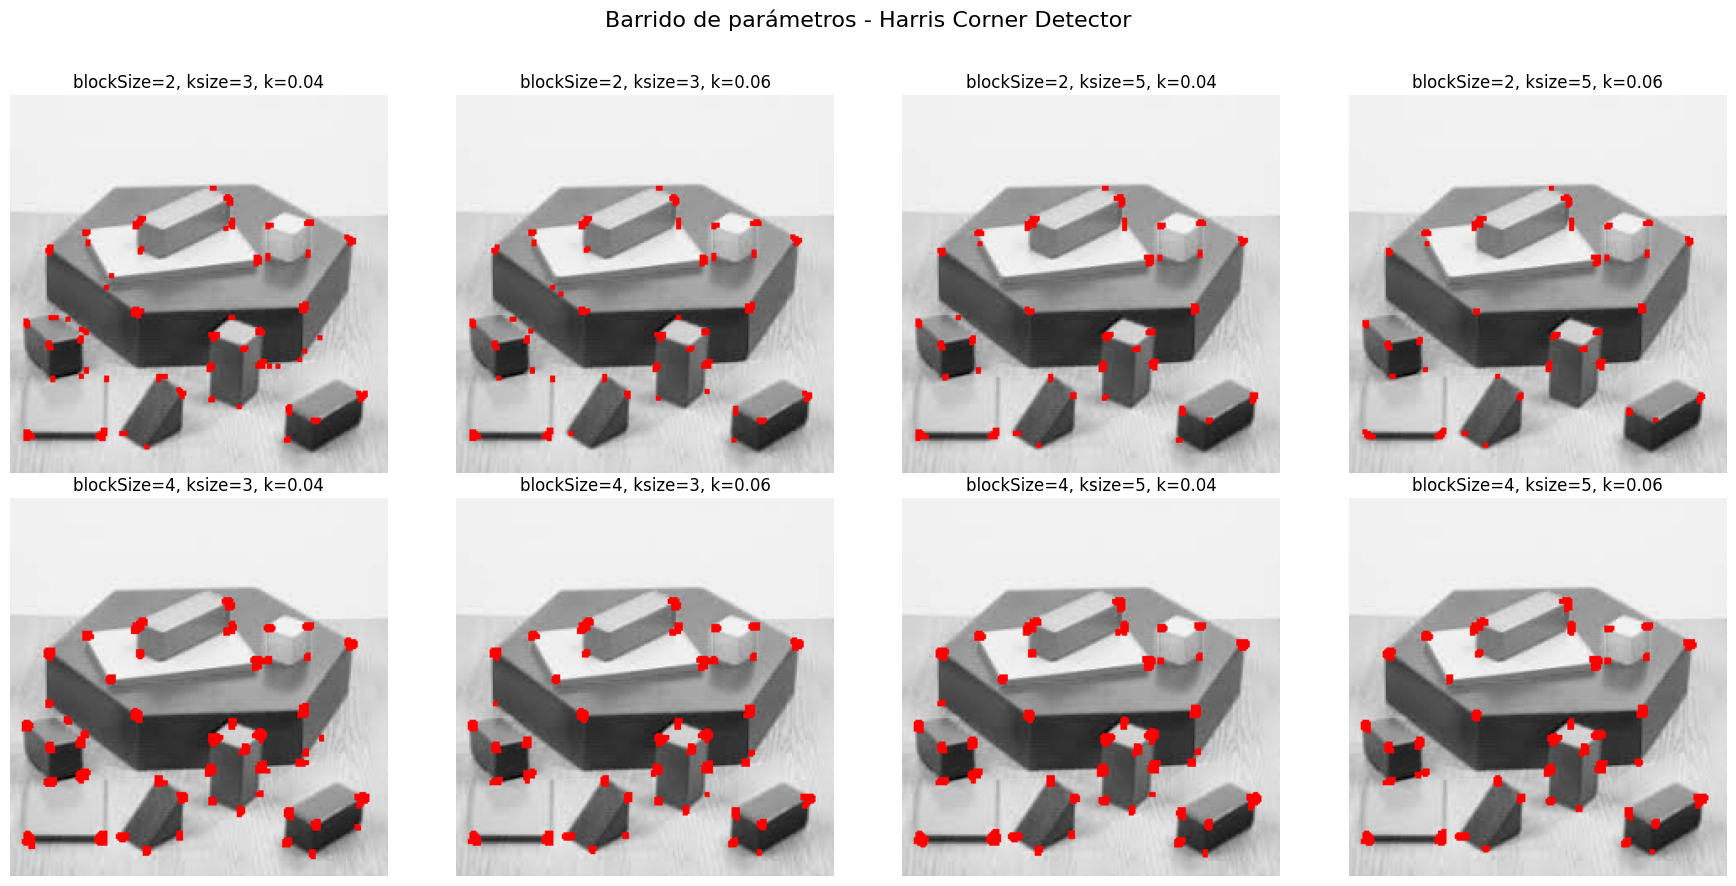

In [ ]:
# Copiamos la imagen base sobre la que haremos las pruebas
image = opencv_images[1].copy()  # por ejemplo, geometry

# Definimos los valores a barrer
blockSizes = [2, 4]
ksizes = [3, 5]
ks = [0.04, 0.06]

# Generamos todas las combinaciones posibles
param_combinations = list(itertools.product(blockSizes, ksizes, ks))

# Preparamos la figura
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.ravel()

for idx, (blockSize, ksize, k) in enumerate(param_combinations):
    # Copiamos imagen original para no sobreescribir
    test_img = image.copy()

    # Aplicamos el detector de Harris
    result = harris_corner_detector(test_img, blockSize, ksize, k)

    # Convertimos a RGB para matplotlib
    result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

    # Mostramos
    axes[idx].imshow(result_rgb)
    axes[idx].set_title(f"blockSize={blockSize}, ksize={ksize}, k={k}")
    axes[idx].axis("off")

plt.suptitle("Barrido de parámetros - Harris Corner Detector", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


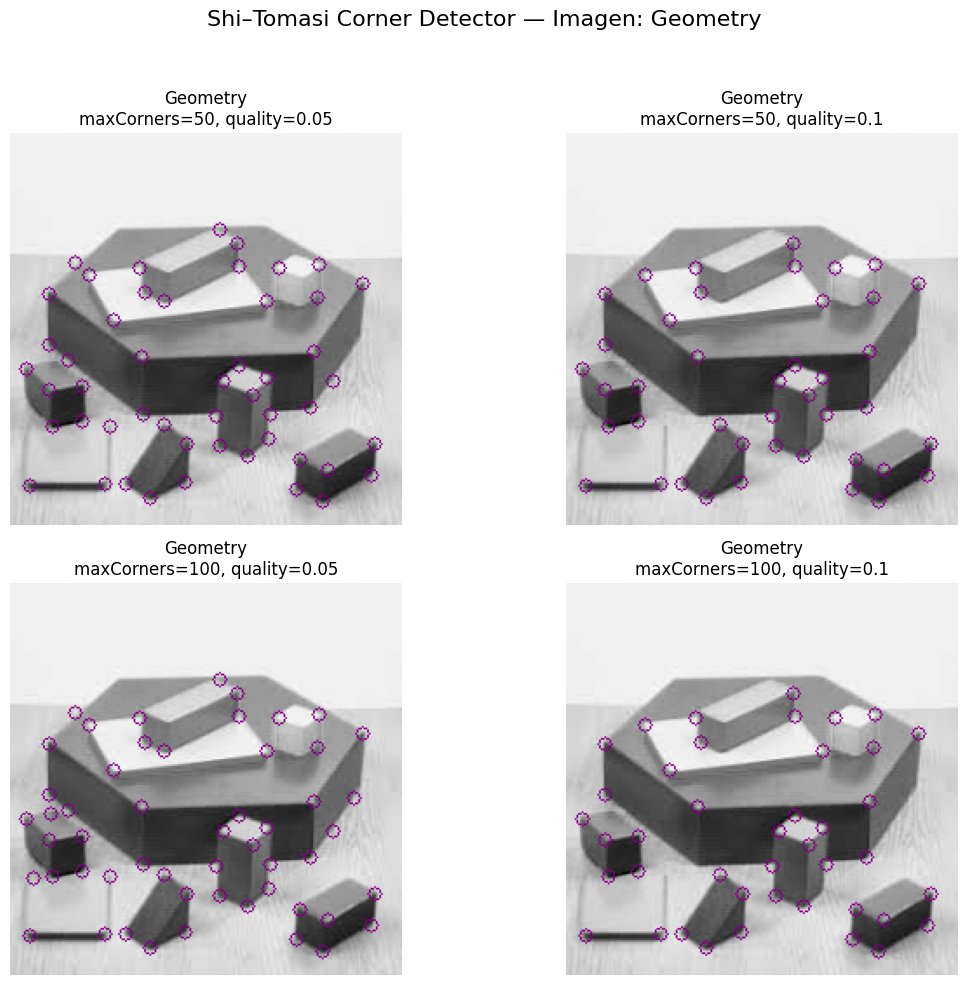

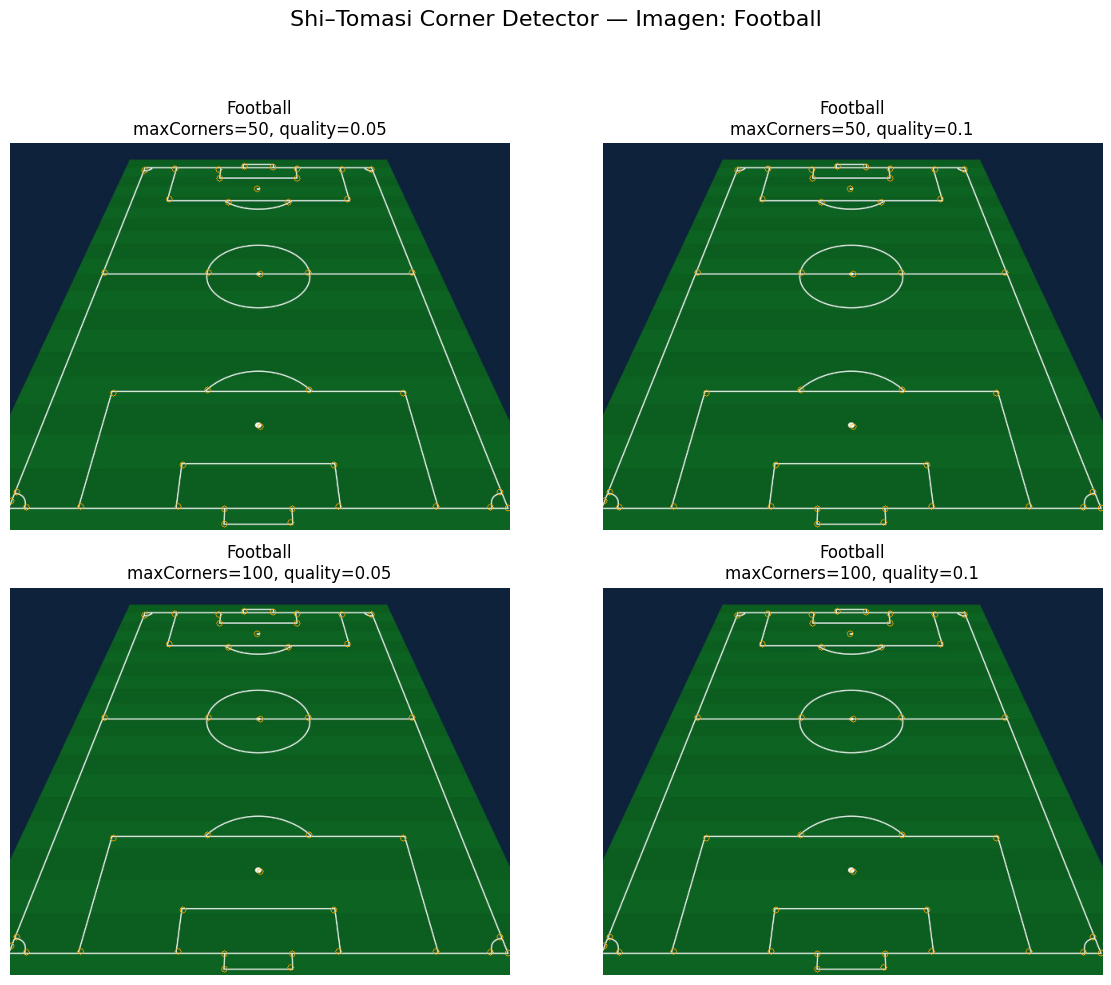

In [42]:
# Imágenes base
geometry_img = opencv_images[1].copy()
football_img = opencv_images[0].copy()

# Parámetros a barrer
maxCorners_values = [50, 100]
qualityLevels = [0.05, 0.1]

# Generamos todas las combinaciones (2x2 = 4)
param_combinations = list(itertools.product(maxCorners_values, qualityLevels))

# ==========================
# FIGURA 1: Geometry
# ==========================
fig1, axes1 = plt.subplots(2, 2, figsize=(12, 10))
axes1 = axes1.ravel()

for idx, (maxCorners, qualityLevel) in enumerate(param_combinations):
    test_img = geometry_img.copy()
    result = shi_tomasi_corner_detection(
        image=test_img,
        maxCorners=maxCorners,
        qualityLevel=qualityLevel,
        minDistance=10,
        corner_color=(128, 0, 128),  # morado
        radius=4
    )

    result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
    axes1[idx].imshow(result_rgb)
    axes1[idx].set_title(f"Geometry\nmaxCorners={maxCorners}, quality={qualityLevel}")
    axes1[idx].axis("off")

plt.suptitle("Shi–Tomasi Corner Detector — Imagen: Geometry", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ==========================
# FIGURA 2: Football
# ==========================
fig2, axes2 = plt.subplots(2, 2, figsize=(12, 10))
axes2 = axes2.ravel()

for idx, (maxCorners, qualityLevel) in enumerate(param_combinations):
    test_img = football_img.copy()
    result = shi_tomasi_corner_detection(
        image=test_img,
        maxCorners=maxCorners,
        qualityLevel=qualityLevel,
        minDistance=10,
        corner_color=(0, 165, 255),  # naranja
        radius=4
    )

    result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
    axes2[idx].imshow(result_rgb)
    axes2[idx].set_title(f"\nFootball\nmaxCorners={maxCorners}, quality={qualityLevel}")
    axes2[idx].axis("off")

plt.suptitle("Shi–Tomasi Corner Detector — Imagen: Football", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### **Pregunta C.1:** Realice la detección de esquinas en las otras dos imágenes de la carpeta ``data/partC-D-E/source`` (cuyos nombres de guardado han de ser "sudoku" y "tennis") con el método de Harris

In [11]:
# Definimos los parámetros que vamos a usar para la función de detección de bordes de Harris (buscando ejemplos en internet y documentaciones parece que son valores aceptables)
blockSize = 2
ksize = 3
k = 0.04

In [12]:
# TODO Homework

# First image
save_name = "sudoku"

# TODO Copy first original image
image = opencv_images[2].copy()

# TODO Apply Harris Corner Detection
harris_image = harris_corner_detector(image, blockSize = blockSize, ksize = ksize, k = k)

# TODO Save final image in partC folder
cv2.imwrite(os.path.join(folder_path, f"Harris_{save_name}.jpg"), harris_image)

# Second image
save_name = "tennis"

# TODO Copy second original image
image = opencv_images[3].copy()

# TODO Apply Harris Corner Detection
harris_image = harris_corner_detector(image, blockSize = blockSize, ksize = ksize, k = k)

# TODO Save final image in partC folder
cv2.imwrite(os.path.join(folder_path, f"Harris_{save_name}.jpg"), harris_image)


True

### **Pregunta C.2:** Realice la detección de esquinas en las otras dos imágenes de la carpeta ``data/partC-D-E/source`` (cuyos nombres de guardado han de ser "sudoku" y "tennis") con el método de Shi-Tomasi

In [13]:
# Definimos los parámetros que vamos a usar para la función de detección de bordes de Harris (buscando ejemplos en internet y documentaciones parece que son valores aceptables)
maxCorners = 100
qualityLevel = 0.05 # no lo dejamos muy bajo para que no nos detecte corners de mala calidad
minDistance = 10
radius = 6

In [14]:
# TODO Homework

# First image - Purple corners and radius = 4
save_name = "sudoku"

# TODO Purple color in adequate color space
orange_color = (0, 165, 255)  # puesto en RGB

# TODO Copy first original image
image = opencv_images[2].copy()

# TODO Apply Shi-Tomasi corner detection
tomasi_image = shi_tomasi_corner_detection(image, maxCorners = maxCorners, qualityLevel = qualityLevel, minDistance = minDistance, corner_color = orange_color, radius = radius)

# TODO Save final image in partC folder
cv2.imwrite(os.path.join(folder_path, f"Shi-Tomasi_{save_name}.jpg"), tomasi_image)

# Second image - Orange corners and radius = 4
save_name = "tennis"

# TODO Orange color in adequate color space
orange_color = (0, 165, 255)  # puesto en RGB

# TODO Copy second original image
image = opencv_images[3].copy()
tomasi_image = shi_tomasi_corner_detection(image, maxCorners = maxCorners, qualityLevel = qualityLevel, minDistance = minDistance, corner_color = orange_color, radius = radius)

# TODO Save final image in partC folder
cv2.imwrite(os.path.join(folder_path, f"Shi-Tomasi_{save_name}.jpg"), tomasi_image)

True